# E-Commerce Sales & Customer Intelligence Analysis

## Business Objective

The objective of this project is to analyze e-commerce transaction data
to understand sales performance, customer purchasing behavior, product
performance, payment patterns, reviews, and delivery performance.

The analysis will use Python, NumPy, Pandas, Matplotlib, and Seaborn
to generate data-driven business insights and recommendations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
orders = pd.read_csv("orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [4]:
orders.shape

(99441, 8)

In [5]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [6]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [7]:
missing_percentage = orders.isnull().mean() *100
missing_percentage

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [8]:
orders['order_id'].duplicated().sum()

np.int64(0)

In [9]:
orders.duplicated().sum()

np.int64(0)

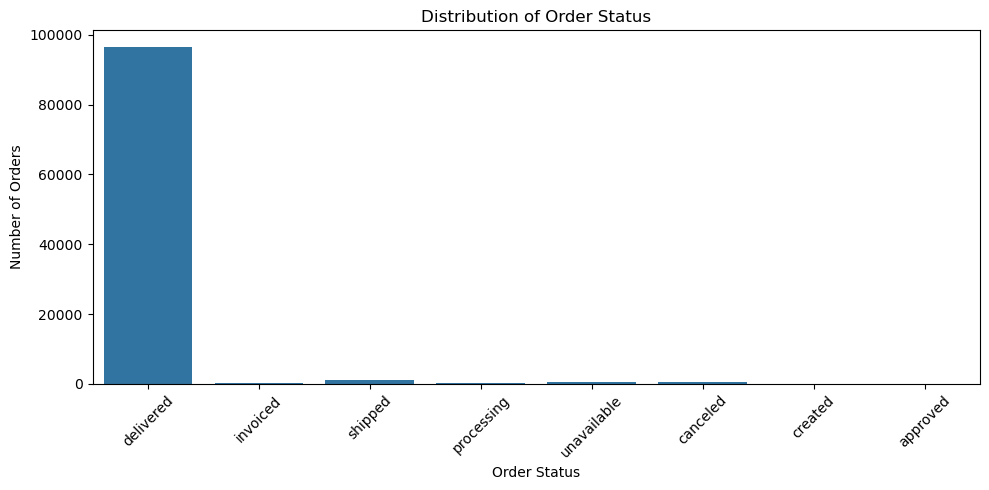

In [10]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=orders,
    x='order_status'
)

plt.title('Distribution of Order Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [11]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

In [12]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  object        
 5   order_delivered_carrier_date   97658 non-null  object        
 6   order_delivered_customer_date  96476 non-null  object        
 7   order_estimated_delivery_date  99441 non-null  object        
dtypes: datetime64[ns](1), object(7)
memory usage: 6.1+ MB


In [13]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [14]:
(orders['order_status']!='delivered').sum()/len(orders)*100

np.float64(2.9796562785973593)

In [15]:
status_summary = orders['order_status'].value_counts().to_frame('order_count')

status_summary['percentage'] = (
    status_summary['order_count'] / len(orders) * 100
)

status_summary

,order_count,percentage
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


In [16]:
orders[['order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date']].head()

,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00
1,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00
2,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00
3,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15 00:00:00
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26 00:00:00


In [17]:
orders[['order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date']].isnull().sum()

order_purchase_timestamp            0
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [18]:
orders[orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [19]:
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

In [20]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  object        
 5   order_delivered_carrier_date   97658 non-null  object        
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](3), object(5)
memory usage: 6.1+ MB


In [21]:
orders['delivery_time_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.total_seconds()/(24*60*60)

In [22]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877


In [23]:
orders['delivery_time_days'].describe()

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_time_days, dtype: float64

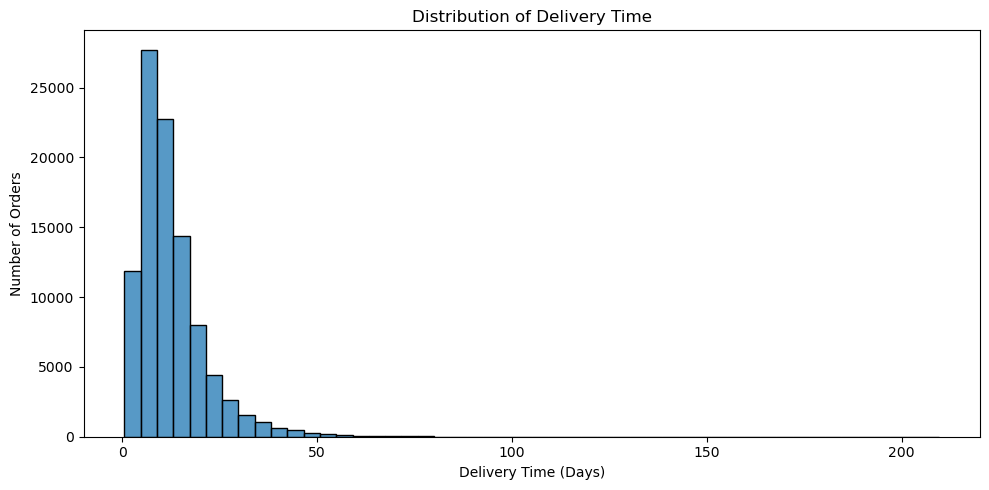

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=orders,
    x='delivery_time_days',
    bins=50
)

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (Days)')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

In [25]:
orders[['order_id','order_status',
     'order_purchase_timestamp',
     'order_delivered_customer_date',
     'delivery_time_days']].sort_values('delivery_time_days', ascending = False).head(10)

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,208.351759
61610,440d0d17af552815d15a9e41abe49359,delivered,2017-03-07 23:59:51,2017-09-19 15:12:50,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,2017-03-08 18:09:02,2017-09-19 14:33:17,194.850174
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,delivered,2017-03-09 13:26:57,2017-09-19 14:38:21,194.049583
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,delivered,2017-03-15 11:24:27,2017-09-19 14:38:18,188.134618
68769,c27815f7e3dd0b926b58552628481575,delivered,2017-03-15 23:23:17,2017-09-19 17:14:25,187.743843


In [26]:
delivered_orders = orders[
    orders['order_delivered_customer_date'].notna()
].copy()

In [27]:
delivered_orders['on_time_delivery'] = (
    delivered_orders['order_delivered_customer_date']
    <= delivered_orders['order_estimated_delivery_date']
)

In [28]:
on_time_rate = delivered_orders['on_time_delivery'].mean() * 100

on_time_rate

np.float64(91.88710145528421)

In [29]:
late_delivery_rate = 100 - on_time_rate

late_delivery_rate

np.float64(8.11289854471579)

In [30]:
delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date']
    - delivered_orders['order_estimated_delivery_date']
).dt.days

In [31]:
delivered_orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96476 entries, 0 to 99440
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96476 non-null  object        
 1   customer_id                    96476 non-null  object        
 2   order_status                   96476 non-null  object        
 3   order_purchase_timestamp       96476 non-null  datetime64[ns]
 4   order_approved_at              96462 non-null  object        
 5   order_delivered_carrier_date   96475 non-null  object        
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  96476 non-null  datetime64[ns]
 8   delivery_time_days             96476 non-null  float64       
 9   on_time_delivery               96476 non-null  bool          
 10  delivery_delay_days            96476 non-null  int64         
dtypes: bool(1), datetime

In [32]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  object        
 5   order_delivered_carrier_date   97658 non-null  object        
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   delivery_time_days             96476 non-null  float64       
dtypes: datetime64[ns](3), float64(1), object(5)
memory usage: 6.8+ MB


In [33]:

late_orders = delivered_orders[
    delivered_orders['delivery_delay_days'] > 0
].copy()

late_orders['delivery_delay_days'].describe()

count    6535.000000
mean       10.620352
std        14.643844
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
Name: delivery_delay_days, dtype: float64

In [34]:
order_items = pd.read_csv("order_items_dataset.csv")
products = pd.read_csv("products_dataset.csv")

In [35]:
order_items.shape, products.shape

((112650, 7), (32951, 9))

In [36]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

In [37]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

In [38]:
order_products = order_items.merge(
                                products[['product_id', 'product_category_name']],
                                   on = 'product_id',
                                   how = 'left'
                                  )

In [39]:
order_products.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [40]:
delivered_orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delivery_time_days', 'on_time_delivery', 'delivery_delay_days'],
      dtype='object')

In [41]:
category_delivery = delivered_orders.merge(
    order_products[['order_id', 'product_category_name']],
    on='order_id',
    how='left'
)

In [42]:
category_delivery['product_category_name'].nunique()

73

In [43]:
category_delivery['product_category_name'].isna().sum()

np.int64(1537)

In [44]:
category_delivery['product_category_name'] = category_delivery['product_category_name'].fillna("Unknown")

In [45]:
category_delivery['product_category_name'].isna().sum()

np.int64(0)

In [46]:
category_delivery['is_late'] = (
    category_delivery['delivery_delay_days'] > 0
)

In [47]:
category_late_rate = (
    category_delivery
    .groupby('product_category_name')['is_late']
    .agg(['count', 'mean'])
    .reset_index()
)

In [48]:
category_late_rate['late_rate'] = (
    category_late_rate['mean'] * 100
)

In [49]:
category_late_rate.head()

,product_category_name,count,mean,late_rate
0,Unknown,1537,0.074821,7.482108
1,agro_industria_e_comercio,206,0.033981,3.398058
2,alimentos,499,0.070140,7.014028
3,alimentos_bebidas,269,0.040892,4.089219
4,artes,197,0.060914,6.091371


In [50]:
category_late_rate = category_late_rate.drop(
    columns='mean'
)

In [51]:
category_late_rate = category_late_rate.sort_values(
    'late_rate',
    ascending=False
)

In [52]:
category_late_rate.head(10)

,product_category_name,count,late_rate
53,moveis_colchao_e_estofado,37,13.513514
16,casa_conforto_2,30,13.333333
8,audio,362,11.602210
7,artigos_de_natal,150,10.000000
40,fashion_underwear_e_moda_praia,127,9.448819
15,casa_conforto,429,9.324009
50,livros_tecnicos,263,7.984791
56,moveis_escritorio,1668,7.973621
10,bebes,2982,7.679410
31,eletronicos,2729,7.585196


In [53]:
reliable_categories = category_late_rate[category_late_rate['count']>=100].copy()

In [54]:
reliable_categories = reliable_categories.sort_values(
    'late_rate',
    ascending=False
)

In [55]:
reliable_categories.head(10)

,product_category_name,count,late_rate
8,audio,362,11.602210
7,artigos_de_natal,150,10.000000
40,fashion_underwear_e_moda_praia,127,9.448819
15,casa_conforto,429,9.324009
50,livros_tecnicos,263,7.984791
56,moveis_escritorio,1668,7.973621
10,bebes,2982,7.679410
31,eletronicos,2729,7.585196
12,beleza_saude,9467,7.573677
0,Unknown,1537,7.482108


In [56]:
order_values = (
    order_items
    .groupby('order_id')
    .agg(
        order_value=('price', 'sum'),
        freight_value=('freight_value', 'sum')
    )
    .reset_index()
)

In [61]:
order_values.head(15)

,order_id,order_value,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,53.99,11.40


In [65]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [68]:
delivery_financials = delivered_orders.merge(
    order_values,
    on='order_id',
    how='left'
)

In [67]:
delivery_financials[
    ['order_id', 'order_value', 'freight_value', 'delivery_delay_days']
].head()

,order_id,order_value,freight_value,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,-8
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,-6
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,-10


In [69]:
delivery_financials['freight_percentage'] = (delivery_financials['freight_value']/delivery_financials['order_value'])*100

In [71]:
delivery_financials[
    ['order_id', 'order_value', 'freight_value', 'freight_percentage']
].head()

,order_id,order_value,freight_value,freight_percentage
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,29.076359
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,19.174389
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,12.020013
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,60.444444
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,43.819095


In [72]:
delivery_financials.groupby('on_time_delivery')[
    ['order_value', 'freight_value', 'freight_percentage']
].mean()

,order_value,freight_value,freight_percentage
on_time_delivery,,,
False,148.070845,24.622275,31.554559
True,136.064080,22.623264,30.775206


In [80]:
order_items.head()
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [81]:
delivered_orders.head()
delivered_orders['order_id'].info()

<class 'pandas.core.series.Series'>
Index: 96476 entries, 0 to 99440
Series name: order_id
Non-Null Count  Dtype 
--------------  ----- 
96476 non-null  object
dtypes: object(1)
memory usage: 1.5+ MB


In [74]:
seller_delivery = delivered_orders.merge(
    order_items[['order_id', 'seller_id']],
    on='order_id',
    how='left'
)

In [83]:
seller_delivery[['order_id', 'seller_id', 'delivery_delay_days']].head()

,order_id,seller_id,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,3504c0cb71d7fa48d967e0e4c94d59d9,-8
1,53cdb2fc8bc7dce0b6741e2150273451,289cdb325fb7e7f891c38608bf9e0962,-6
2,47770eb9100c2d0c44946d9cf07ec65d,4869f7a5dfa277a7dca6462dcf3b52b2,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,66922902710d126a0e7d26b0e3805106,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,2c9e548be18521d1c43cde1c582c6de8,-10


In [85]:
seller_late_rate.head()

,seller_id,total_orders,average_delay
0,0015a82c2db000af6aaaf3ae2ecb0532,3,-16.333333
1,001cca7ae9ae17fb1caed9dfb1094831,234,-13.213675
2,002100f778ceb8431b7a1020ff7ab48f,54,-8.185185
3,003554e2dce176b5555353e4f3555ac8,1,-27.000000
4,004c9cd9d87a3c30c522c48c4fc07416,168,-11.982143


In [86]:
seller_delivery['is_late'] = (
    seller_delivery['delivery_delay_days'] > 0
)

In [87]:
seller_late_rate = (
    seller_delivery
    .groupby('seller_id')
    .agg(
        total_orders=('order_id', 'count'),
        late_orders=('is_late', 'sum'),
        average_delay=('delivery_delay_days', 'mean')
    )
    .reset_index()
)

In [88]:
seller_late_rate['late_rate'] = (
    seller_late_rate['late_orders']
    / seller_late_rate['total_orders']
    * 100
)

In [89]:
reliable_sellers = seller_late_rate[
    seller_late_rate['total_orders'] >= 50
].copy()

In [91]:
reliable_sellers = reliable_sellers.sort_values(
    'late_rate',
    ascending=False
)

In [92]:
reliable_sellers.head(10)

,seller_id,total_orders,late_orders,average_delay,late_rate
1000,54965bbe3e4f07ae045b90b0b8541f52,81,26,-2.395062,32.098765
478,2a1348e9addc1af5aaa619b1a3679d6b,51,15,0.705882,29.411765
2171,bbad7e518d7af88a0897397ffdca1979,84,19,-7.023810,22.619048
2211,beadbee30901a7f61d031b6b686095ad,68,15,-9.661765,22.058824
1141,6039e27294dc75811c0d8a39069f52c0,74,16,-7.094595,21.621622
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,104,22,-4.586538,21.153846
1139,602044f2c16190c2c6e45eb35c2e21cb,55,11,-8.127273,20.000000
1336,712e6ed8aa4aa1fa65dab41fed5737e4,85,17,-9.811765,20.000000
480,2a261b5b644fa05f4f2700eb93544f2c,82,16,-9.109756,19.512195
79,06a2c3af7b3aee5d69171b0e14f0ee87,402,78,-11.263682,19.402985


In [93]:
seller_late_rate = (
    seller_delivery
    .groupby('seller_id')
    .agg(
        total_orders=('order_id', 'nunique'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)

In [94]:
seller_late_rate['late_rate'] = (
    seller_late_rate['late_orders']
    / seller_late_rate['total_orders']
    * 100
)

In [95]:
late_seller_orders = seller_delivery[
    seller_delivery['is_late']
].groupby('seller_id')['delivery_delay_days'].mean().reset_index()

late_seller_orders = late_seller_orders.rename(
    columns={'delivery_delay_days': 'average_late_delay'}
)

In [97]:
seller_late_rate = seller_late_rate.merge(
    late_seller_orders,
    on='seller_id',
    how='left')

In [98]:
reliable_sellers = seller_late_rate[
    seller_late_rate['total_orders'] >= 50
].copy()

In [99]:
reliable_sellers = reliable_sellers.sort_values(
    'late_rate',
    ascending=False
)

In [100]:
reliable_sellers.head(10)

,seller_id,total_orders,late_orders,late_rate,average_late_delay
1000,54965bbe3e4f07ae045b90b0b8541f52,73,26,35.616438,27.307692
480,2a261b5b644fa05f4f2700eb93544f2c,51,16,31.372549,9.062500
2171,bbad7e518d7af88a0897397ffdca1979,68,19,27.941176,9.684211
1141,6039e27294dc75811c0d8a39069f52c0,63,16,25.396825,7.375000
2211,beadbee30901a7f61d031b6b686095ad,64,15,23.437500,7.133333
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,22,22.916667,8.954545
513,2c9e548be18521d1c43cde1c582c6de8,124,28,22.580645,17.000000
1336,712e6ed8aa4aa1fa65dab41fed5737e4,77,17,22.077922,19.705882
160,0d85bbda9889ce1f7e63778d24f346eb,51,11,21.568627,7.272727
203,11bfa66332777660bd0640ee84d47006,76,16,21.052632,9.875000


In [101]:
customers = pd.read_csv("customers_dataset.csv")

In [102]:
customers.shape

(99441, 5)

In [103]:
customers.columns


Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [107]:
geo_delivery = delivered_orders.merge(customers[['customer_id', 'customer_city', 'customer_state']],
                                      on = 'customer_id',
                                      how = 'left')

In [108]:
geo_delivery.shape

(96476, 13)

In [110]:
geo_delivery[['customer_state', 'customer_city']].head()

,customer_state,customer_city
0,SP,sao paulo
1,BA,barreiras
2,GO,vianopolis
3,RN,sao goncalo do amarante
4,SP,santo andre


In [111]:
geo_delivery['is_late'] = (
    geo_delivery['delivery_delay_days'] > 0
)

state_late_rate = (
    geo_delivery
    .groupby('customer_state')
    .agg(
        total_orders=('order_id', 'nunique'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)

state_late_rate['late_rate'] = (
    state_late_rate['late_orders']
    / state_late_rate['total_orders']
    * 100
)

reliable_states = state_late_rate[
    state_late_rate['total_orders'] >= 100
].copy()

reliable_states = reliable_states.sort_values(
    'late_rate',
    ascending=False
)

reliable_states.head(10)

,customer_state,total_orders,late_orders,late_rate
1,AL,397,85,21.410579
9,MA,717,125,17.433752
24,SE,335,51,15.223881
16,PI,476,66,13.865546
5,CE,1279,176,13.760751
4,BA,3256,396,12.162162
18,RJ,12353,1495,12.102323
13,PA,946,106,11.205074
7,ES,1995,214,10.726817
14,PB,517,54,10.444874


In [112]:
delivered_orders['order_purchase_timestamp'].head()

0   2017-10-02 10:56:33
1   2018-07-24 20:41:37
2   2018-08-08 08:38:49
3   2017-11-18 19:28:06
4   2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: datetime64[ns]

In [113]:
delivered_orders['purchase_month'] = (
    delivered_orders['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)

In [114]:
monthly_delivery = (
    delivered_orders
    .groupby('purchase_month')
    .agg(
        total_orders=('order_id', 'nunique'),
        late_orders=('delivery_delay_days', lambda x: (x > 0).sum())
    )
    .reset_index()
)

monthly_delivery['late_rate'] = (
    monthly_delivery['late_orders']
    / monthly_delivery['total_orders']
    * 100
)

monthly_delivery

,purchase_month,total_orders,late_orders,late_rate
0,2016-09,1,1,100.000000
1,2016-10,270,2,0.740741
2,2016-12,1,0,0.000000
3,2017-01,750,22,2.933333
4,2017-02,1653,49,2.964307
5,2017-03,2546,116,4.556167
6,2017-04,2303,151,6.556665
7,2017-05,3545,106,2.990127
8,2017-06,3135,95,3.030303
9,2017-07,3872,108,2.789256


In [115]:
customer_orders = delivered_orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

In [116]:
customer_frequency = (
    customer_orders
    .groupby('customer_unique_id')
    .agg(
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

In [117]:
customer_frequency['total_orders'].describe()

count    93356.00000
mean         1.03342
std          0.20910
min          1.00000
25%          1.00000
50%          1.00000
75%          1.00000
max         15.00000
Name: total_orders, dtype: float64

In [118]:
repeat_customers = customer_frequency[
    customer_frequency['total_orders'] > 1
]

repeat_customer_rate = (
    len(repeat_customers)
    / len(customer_frequency)
    * 100
)

repeat_customer_rate

3.0003427738977675

In [119]:
customer_spending = customer_orders.merge(
    order_values,
    on='order_id',
    how='left'
)


In [121]:
customer_spending_summary = (
    customer_spending
    .groupby('customer_unique_id')
    .agg(
        total_spending=('order_value', 'sum'),
        total_orders=('order_id', 'nunique')
    )
    .reset_index()
    
)


In [122]:
customer_spending_summary.sort_values(
    'total_spending',
    ascending=False
).head(10)

,customer_unique_id,total_spending,total_orders
3724,0a0a92112bd4c708ca5fde585afaa872,13440.0,1
79634,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2
43166,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1
80461,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1
25432,459bef486812aa25204be022145caa62,6729.0,1
93079,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1
23407,4007669dec559734d6f53e029e360987,5934.6,1
87145,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1
26636,48e1ac109decbb87765a3eade6854098,4590.0,1
59161,a229eba70ec1c2abef51f04987deb7a5,4400.0,1


In [123]:
seller_orders = seller_delivery[
    ['order_id', 'seller_id', 'delivery_delay_days']
].drop_duplicates(
    subset=['order_id', 'seller_id']
)

In [124]:
seller_orders['is_late'] = (
    seller_orders['delivery_delay_days'] > 0
)

In [126]:
seller_performance = (
    seller_orders
    .groupby('seller_id')
    .agg(
        total_orders=('order_id', 'nunique'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)

seller_performance['late_rate'] = (
    seller_performance['late_orders']
    / seller_performance['total_orders']
    * 100
)


In [127]:
reliable_sellers = seller_performance[
    seller_performance['total_orders'] >= 50
].copy()

In [128]:
reliable_sellers = reliable_sellers.sort_values(
    'late_rate',
    ascending=False
)

reliable_sellers.head(10)

,seller_id,total_orders,late_orders,late_rate
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,30.136986
2211,beadbee30901a7f61d031b6b686095ad,64,15,23.437500
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,21,21.875000
1336,712e6ed8aa4aa1fa65dab41fed5737e4,77,16,20.779221
79,06a2c3af7b3aee5d69171b0e14f0ee87,389,74,19.023136
2720,ea566164622c6b439516ab18062c42cd,50,9,18.000000
2,002100f778ceb8431b7a1020ff7ab48f,50,9,18.000000
2365,cac4c8e7b1ca6252d8f20b2fc1a2e4af,74,13,17.567568
1141,6039e27294dc75811c0d8a39069f52c0,63,11,17.460317
1606,88460e8ebdecbfecb5f9601833981930,246,42,17.073171


In [130]:
category_orders = category_delivery[
    ['order_id', 'product_category_name', 'delivery_delay_days']
].drop_duplicates(
    subset=['order_id', 'product_category_name']
)

In [131]:
category_orders['is_late'] = (
    category_orders['delivery_delay_days'] > 0
)

In [132]:
category_performance = (
    category_orders
    .groupby('product_category_name')
    .agg(
        total_orders=('order_id', 'nunique'),
        late_orders=('is_late', 'sum')
    )
    .reset_index()
)

category_performance['late_rate'] = (
    category_performance['late_orders']
    / category_performance['total_orders']
    * 100
)

In [133]:
reliable_categories = category_performance[
    category_performance['total_orders'] >= 100
].copy()

In [134]:
reliable_categories = reliable_categories.sort_values(
    'late_rate',
    ascending=False
)

reliable_categories.head(10)

,product_category_name,total_orders,late_orders,late_rate
8,audio,348,41,11.781609
15,casa_conforto,392,37,9.438776
40,fashion_underwear_e_moda_praia,117,11,9.401709
50,livros_tecnicos,256,21,8.203125
56,moveis_escritorio,1254,101,8.054226
10,bebes,2809,226,8.045568
7,artigos_de_natal,125,10,8.000000
31,eletronicos,2517,192,7.628129
46,instrumentos_musicais,611,46,7.528642
12,beleza_saude,8649,650,7.515320


In [135]:
total_delivered = len(delivered_orders)

on_time_orders = (
    delivered_orders['on_time_delivery'].sum()
)

late_orders = (
    delivered_orders['delivery_delay_days'] > 0
).sum()

overall_on_time_rate = (
    on_time_orders / total_delivered * 100
)

overall_late_rate = (
    late_orders / total_delivered * 100
)

average_delay_late = (
    delivered_orders.loc[
        delivered_orders['delivery_delay_days'] > 0,
        'delivery_delay_days'
    ].mean()
)

print("Total delivered orders:", total_delivered)
print("On-time delivery rate:", round(overall_on_time_rate, 2), "%")
print("Late delivery rate:", round(overall_late_rate, 2), "%")
print("Average delay among late orders:", round(average_delay_late, 2), "days")

Total delivered orders: 96476
On-time delivery rate: 91.89 %
Late delivery rate: 6.77 %
Average delay among late orders: 10.62 days


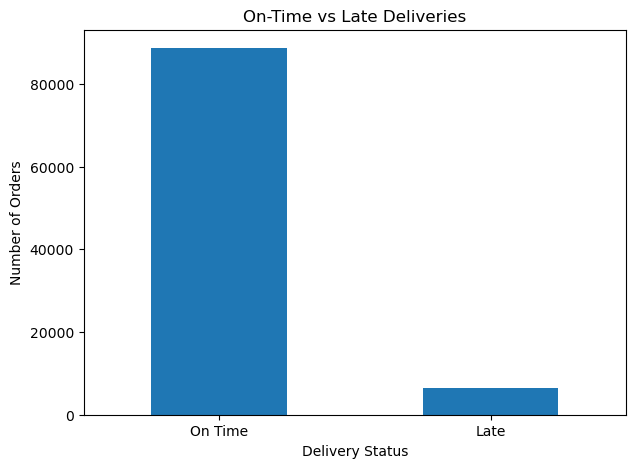

In [136]:
import matplotlib.pyplot as plt

delivery_status = pd.Series({
    'On Time': on_time_orders,
    'Late': late_orders
})

delivery_status.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('On-Time vs Late Deliveries')
plt.ylabel('Number of Orders')
plt.xlabel('Delivery Status')
plt.xticks(rotation=0)
plt.show()

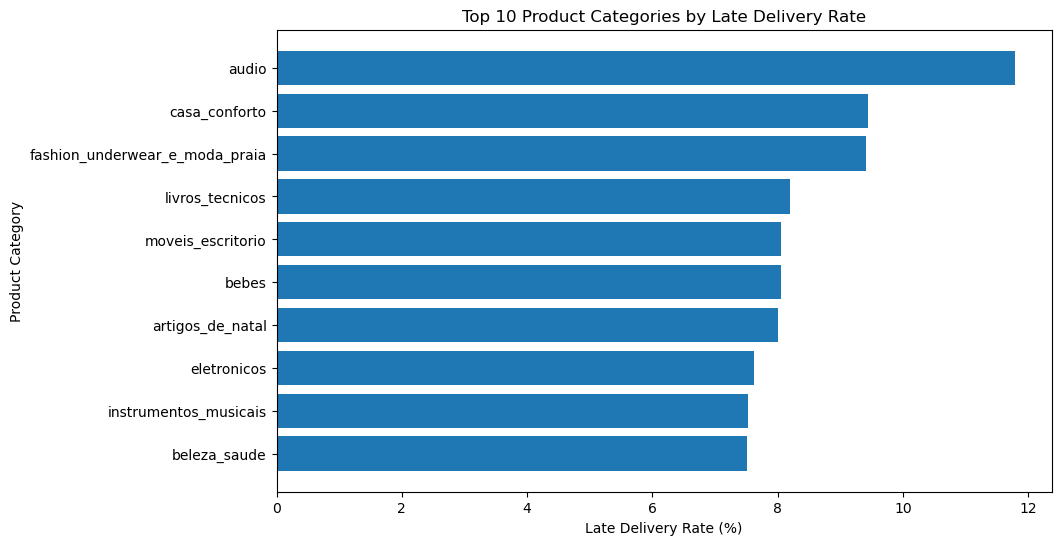

In [137]:
top_categories = reliable_categories.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories['product_category_name'],
    top_categories['late_rate']
)

plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Product Category')
plt.title('Top 10 Product Categories by Late Delivery Rate')
plt.gca().invert_yaxis()

plt.show()

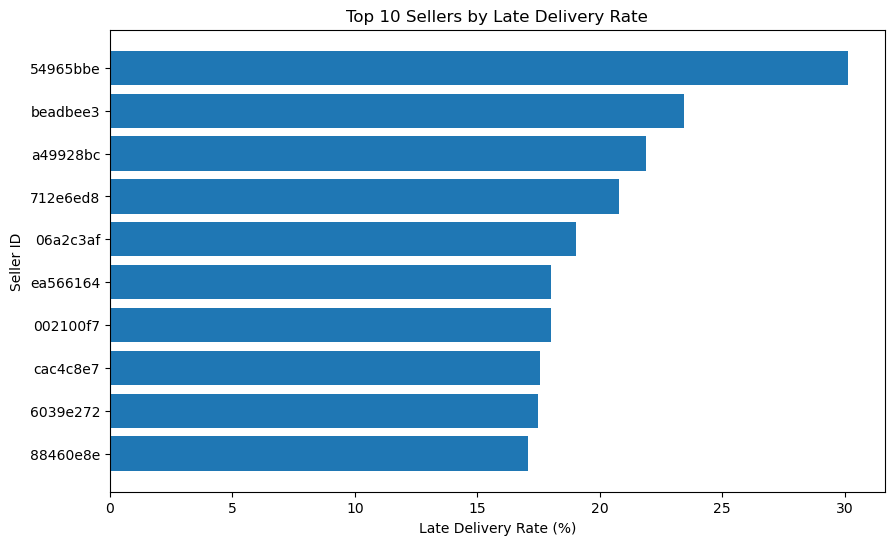

In [138]:
top_sellers = reliable_sellers.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_sellers['seller_id'].str[:8],
    top_sellers['late_rate']
)

plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Seller ID')
plt.title('Top 10 Sellers by Late Delivery Rate')
plt.gca().invert_yaxis()

plt.show()

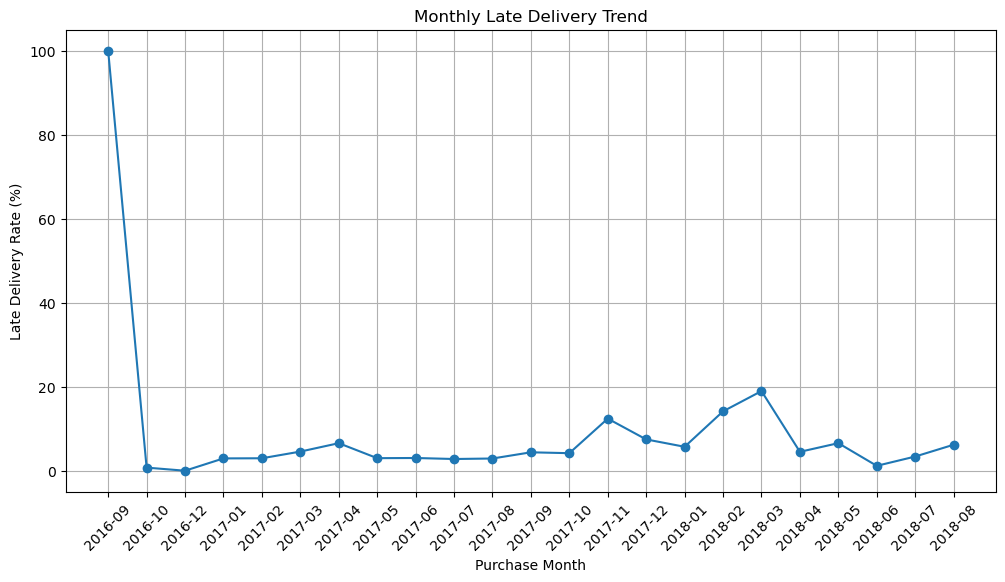

In [139]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_delivery['purchase_month'],
    monthly_delivery['late_rate'],
    marker='o'
)

plt.xlabel('Purchase Month')
plt.ylabel('Late Delivery Rate (%)')
plt.title('Monthly Late Delivery Trend')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

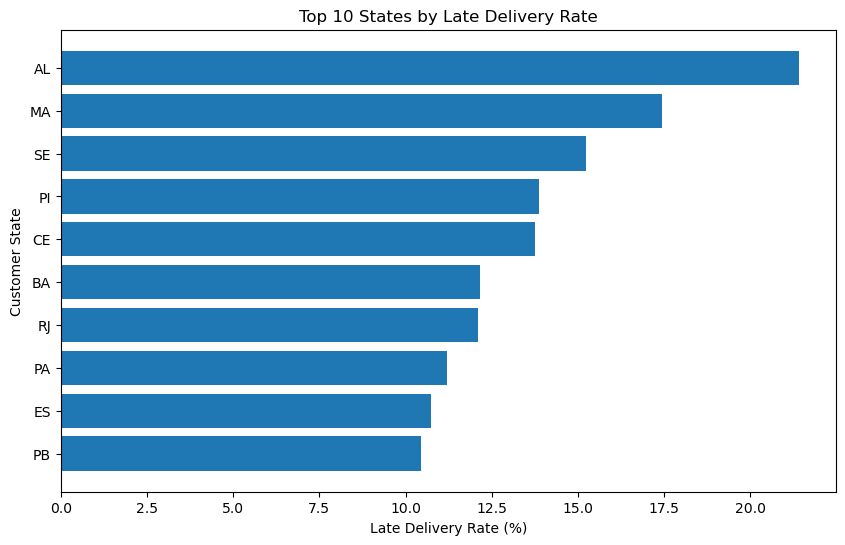

In [140]:
top_states = reliable_states.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states['customer_state'],
    top_states['late_rate']
)

plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Customer State')
plt.title('Top 10 States by Late Delivery Rate')

plt.gca().invert_yaxis()

plt.show()

In [141]:
reliable_categories.head(10)

,product_category_name,total_orders,late_orders,late_rate
8,audio,348,41,11.781609
15,casa_conforto,392,37,9.438776
40,fashion_underwear_e_moda_praia,117,11,9.401709
50,livros_tecnicos,256,21,8.203125
56,moveis_escritorio,1254,101,8.054226
10,bebes,2809,226,8.045568
7,artigos_de_natal,125,10,8.000000
31,eletronicos,2517,192,7.628129
46,instrumentos_musicais,611,46,7.528642
12,beleza_saude,8649,650,7.515320


In [142]:
reliable_sellers.head(10)

,seller_id,total_orders,late_orders,late_rate
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,30.136986
2211,beadbee30901a7f61d031b6b686095ad,64,15,23.437500
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,21,21.875000
1336,712e6ed8aa4aa1fa65dab41fed5737e4,77,16,20.779221
79,06a2c3af7b3aee5d69171b0e14f0ee87,389,74,19.023136
2720,ea566164622c6b439516ab18062c42cd,50,9,18.000000
2,002100f778ceb8431b7a1020ff7ab48f,50,9,18.000000
2365,cac4c8e7b1ca6252d8f20b2fc1a2e4af,74,13,17.567568
1141,6039e27294dc75811c0d8a39069f52c0,63,11,17.460317
1606,88460e8ebdecbfecb5f9601833981930,246,42,17.073171


In [143]:
reliable_states.head(10)

,customer_state,total_orders,late_orders,late_rate
1,AL,397,85,21.410579
9,MA,717,125,17.433752
24,SE,335,51,15.223881
16,PI,476,66,13.865546
5,CE,1279,176,13.760751
4,BA,3256,396,12.162162
18,RJ,12353,1495,12.102323
13,PA,946,106,11.205074
7,ES,1995,214,10.726817
14,PB,517,54,10.444874


In [144]:
monthly_delivery.sort_values(
    'late_rate',
    ascending=False
).head(10)

,purchase_month,total_orders,late_orders,late_rate
0,2016-09,1,1,100.000000
17,2018-03,7003,1328,18.963301
16,2018-02,6556,927,14.139719
13,2017-11,7288,904,12.403952
14,2017-12,5513,411,7.455106
19,2018-05,6749,443,6.563935
6,2017-04,2303,151,6.556665
22,2018-08,6351,393,6.188002
15,2018-01,7069,403,5.700948
5,2017-03,2546,116,4.556167
